**LINEAR REGRESSION**



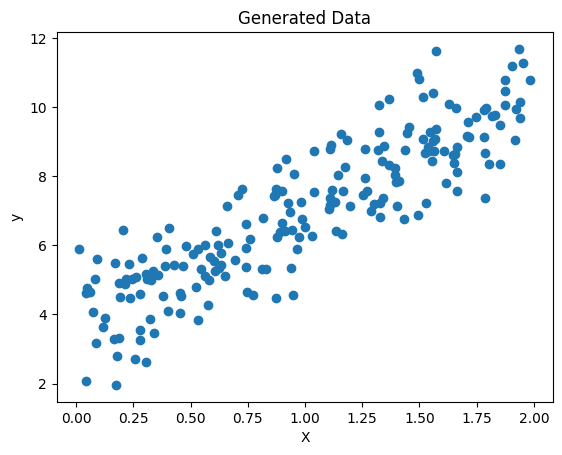

In [26]:
# Generating sample data for linear regression
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(seed=42)
m = 200
X = 2 * rng.random((m, 1))
y = 4 + 3 * X + rng.standard_normal((m, 1))
plt.scatter(X, y)
plt.xlabel("X")
plt.ylabel("y")
plt.title("Generated Data")
plt.show()

In [27]:
#Computing best-fit parameters using the Normal Equation
from sklearn.preprocessing import add_dummy_feature

X_b = add_dummy_feature(X)
theta_best = np.linalg.inv(X_b.T @ X_b)@(X_b.T)@(y)
print("Best-fit parameters (theta):", theta_best.ravel())


Best-fit parameters (theta): [3.69084138 3.32960458]


Predictions for new data points: [ 3.69084138 10.35005055]


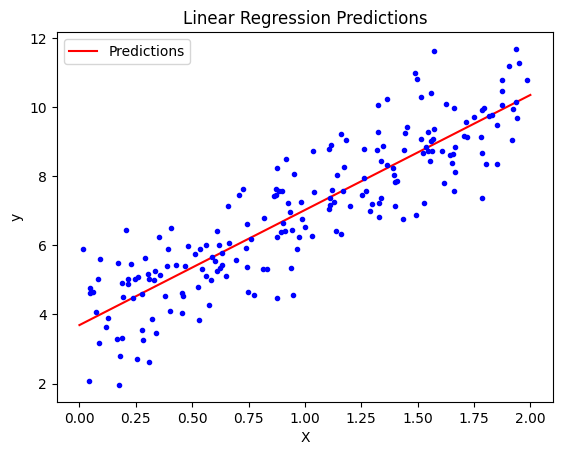

In [28]:
# Making predictions with the computed parameters
X_new = np.array([[0], [2]])
X_new_b = add_dummy_feature(X_new)
y_predict = X_new_b @ theta_best
print("Predictions for new data points:", y_predict.ravel())

plt.plot(X_new, y_predict, "r-", label="Predictions")
plt.plot(X, y, "b.")
plt.xlabel("X")
plt.ylabel("y")
plt.title("Linear Regression Predictions")
plt.legend()
plt.show()

In [29]:
# Using Scikit-Learn's LinearRegression
from sklearn.linear_model import LinearRegression

lin_reg = LinearRegression()
lin_reg.fit(X, y)
print(lin_reg.intercept_, lin_reg.coef_)

lin_reg.predict(X_new)

[3.69084138] [[3.32960458]]


array([[ 3.69084138],
       [10.35005055]])

In [30]:
# Computing best-fit parameters using SVD that underlies the Pseudo-Inverse (1) 
# Alternatively direcytly using the Pseudo-Inverse (2)
theta_best_svd, residuals, rank, s = np.linalg.lstsq(X_b, y, rcond=1e-6)
print("Best-fit parameters using SVD (theta):", theta_best_svd.ravel())
print(np.linalg.pinv(X_b) @ y)

Best-fit parameters using SVD (theta): [3.69084138 3.32960458]
[[3.69084138]
 [3.32960458]]


 **GRADIENT DESCENT**


In [31]:
#GRADIENT SIMPLE DESCENT
eta = 0.1  # Learning rate
n_epochs = 1000 # Number of iterations
m = len(X_b)  # Number of samples
theta = rng.standard_normal((2,1))  # Random initialization of parameters

for epoch in range(n_epochs):
    gradients = 2/m * X_b.T @ (X_b @ theta - y)
    theta = theta - eta * gradients

print("Best-fit parameters using Gradient Descent (theta):", theta.ravel())

Best-fit parameters using Gradient Descent (theta): [3.69084138 3.32960458]


In [32]:
#STOCHASTIC GRADIENT DESCENT
n_epochs = 50
t0, t1 = 5, 50  # Learning schedule hyperparameters

def learning_schedule(t):
    return t0 / (t + t1)

rng = np.random.default_rng(seed=42)
theta = rng.standard_normal((2,1))  # Random initialization of parameters

for epoch in range(n_epochs):
    for i in range(m):
        random_index = rng.integers(m)
        xi = X_b[random_index:random_index+1]
        yi = y[random_index:random_index+1]
        gradients = 2 * xi.T @ (xi @ theta - yi)
        eta = learning_schedule(epoch * m + i)
        theta = theta - eta * gradients

print("Best-fit parameters using Stochastic Gradient Descent (theta):", theta.ravel())     


Best-fit parameters using Stochastic Gradient Descent (theta): [3.69826475 3.30748311]


In [33]:
# Using Scikit-Learn's SGDRegressor
from sklearn.linear_model import SGDRegressor

sgd_reg = SGDRegressor(max_iter=1000, tol=1e-3, penalty=None, eta0=0.01, random_state=42, n_iter_no_change=100)

sgd_reg.fit(X, y.ravel())
print("Best-fit parameters using SGDRegressor (intercept and coef):", sgd_reg.intercept_, sgd_reg.coef_)

Best-fit parameters using SGDRegressor (intercept and coef): [3.67403001] [3.33720161]


**POLYNOMIAL REGRESSION**


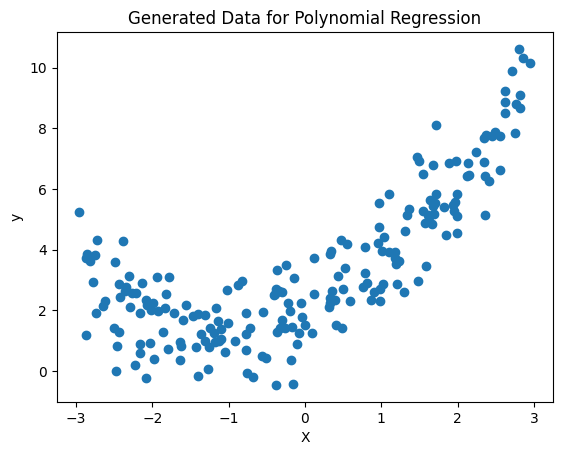

[1.64373629 2.701869  ]
Best-fit parameters for Polynomial Regression (intercept and coef): [2.00540719] [[1.11022126 0.50526985]]


In [34]:
# POLYNOMIAL REGRESSION applying Linear Regression on transformed features
rng = np.random.default_rng(seed=42)
m = 200 # Number of samples
X = 6 * rng.random((m, 1)) - 3
y = 0.5 * X**2 + X + 2 + rng.standard_normal((m, 1))  # Quadratic relationship with noise
plt.scatter(X, y)
plt.xlabel("X")
plt.ylabel("y")
plt.title("Generated Data for Polynomial Regression")
plt.show()

from sklearn.preprocessing import PolynomialFeatures
poly_features = PolynomialFeatures(degree=2, include_bias=False)
X_poly = poly_features.fit_transform(X)
print(X_poly[0])

lin_reg = LinearRegression()
lin_reg.fit(X_poly, y)
print("Best-fit parameters for Polynomial Regression (intercept and coef):", lin_reg.intercept_, lin_reg.coef_)


**LEARNING CURVE**


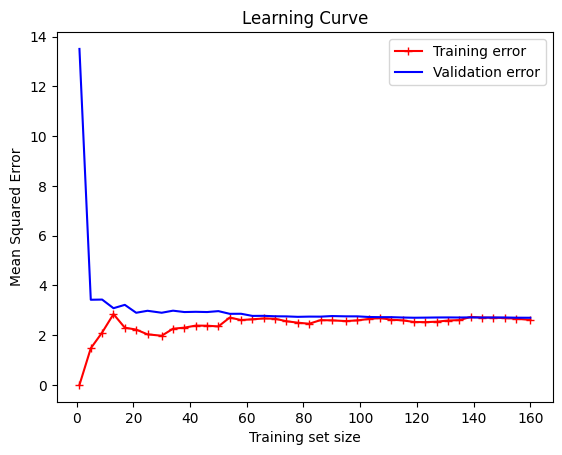

In [35]:
#LEARNING CURVE to evaluate how the model's performance changes with varying training set sizes
from sklearn.model_selection import learning_curve

train_sizes, train_scores, valid_scores = learning_curve(
    LinearRegression(), X, y, train_sizes=np.linspace(0.01, 1.0, 40), cv=5, scoring='neg_mean_squared_error')

train_errors = -train_scores.mean(axis=1)
valid_errors = -valid_scores.mean(axis=1)

plt.plot(train_sizes, train_errors, "r-+", label="Training error")
plt.plot(train_sizes, valid_errors, "b-", label="Validation error")
plt.xlabel("Training set size")
plt.ylabel("Mean Squared Error")
plt.title("Learning Curve")
plt.legend()
plt.show()


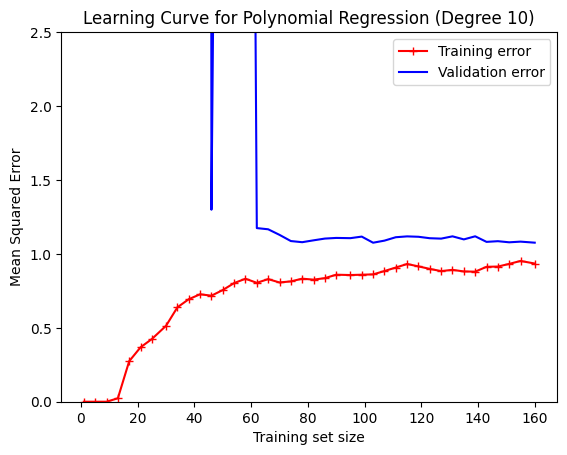

In [36]:
#LEARNING CURVE for Polynomial Regression (Degree 10)
from sklearn.pipeline import make_pipeline

polynomial_regression = make_pipeline(
    PolynomialFeatures(degree=10, include_bias=False),
    LinearRegression()
)

train_sizes, train_scores, valid_scores = learning_curve(
    polynomial_regression, X, y, train_sizes=np.linspace(0.01, 1.0, 40), cv=5, scoring='neg_mean_squared_error')

train_errors = -train_scores.mean(axis=1)
valid_errors = -valid_scores.mean(axis=1)   
plt.plot(train_sizes, train_errors, "r-+", label="Training error")
plt.plot(train_sizes, valid_errors, "b-", label="Validation error")
plt.ylim(0, 2.5)
plt.yticks(np.arange(0, 2.5 + 0.001, 0.5))
plt.xlabel("Training set size")
plt.ylabel("Mean Squared Error")
plt.title("Learning Curve for Polynomial Regression (Degree 10)")
plt.legend()
plt.show()

**REGULARIZATION**



In [41]:
#Ridge Regression (L2 Regularization)

from sklearn.linear_model import Ridge

ridge_reg = Ridge(alpha = 0.1, solver="cholesky")
ridge_reg.fit(X, y)
print("Best-fit parameters for Ridge Regression (intercept and coef):", ridge_reg.intercept_, ridge_reg.coef_)

print("Predicted value for input [[1.5]]:", ridge_reg.predict([[1.5]]))

Best-fit parameters for Ridge Regression (intercept and coef): [3.4473073] [1.07618083]
Predicted value for input [[1.5]]: [5.06157854]


In [ ]:
#SGDRegressor with L2 regularization (Ridge Regression)
sgd_reg = SGDRegressor(penalty = "l2", 
                       alpha = 0.1/m, 
                       max_iter=1000, 
                       tol=None,
                       eta0=0.01, 
                       n_iter_no_change=100)

sgd_reg.fit(X, y.ravel())
print("Best-fit parameters using SGDRegressor with L2 regularization (intercept and coef):", sgd_reg.intercept_, sgd_reg.coef_)
print("Predicted value for input [[1.5]] with SGDRegressor:", sgd_reg.predict([[1.5]]))

Best-fit parameters using SGDRegressor with L2 regularization (intercept and coef): [3.44989827] [1.07584896]
Predicted value for input [[1.5]] with SGDRegressor: [5.06367171]


In [43]:
#LASSO Regression (L1 Regularization)

from sklearn.linear_model import Lasso

lasso_reg = Lasso(alpha=0.1)
lasso_reg.fit(X, y)
print("Best-fit parameters for Lasso Regression (intercept and coef):", lasso_reg
.intercept_, lasso_reg.coef_)
print("Predicted value for input [[1.5]]:", lasso_reg.predict([[1.5]]))



Best-fit parameters for Lasso Regression (intercept and coef): [3.4460258] [1.04134117]
Predicted value for input [[1.5]]: [5.00803756]


In [44]:
#SGDRegressor with L1 regularization (Lasso Regression)

sgd_reg_l1 = SGDRegressor(penalty = "l1",
                            alpha = 0.1)
sgd_reg_l1.fit(X, y.ravel())
print("Best-fit parameters using SGDRegressor with L1 regularization (intercept and coef):", sgd_reg_l1.intercept_, sgd_reg_l1.coef_)
print("Predicted value for input [[1.5]] with SGDRegressor L1:", sgd_reg_l1.predict([[1.5]]))


Best-fit parameters using SGDRegressor with L1 regularization (intercept and coef): [3.43497045] [1.05363425]
Predicted value for input [[1.5]] with SGDRegressor L1: [5.01542182]


In [46]:
#Elastic Net (Combination of L1 and L2 Regularization)

from sklearn.linear_model import ElasticNet

elastic_net = ElasticNet(alpha = 0.1, l1_ratio=0.5)
elastic_net.fit(X, y)
print("Best-fit parameters for Elastic Net (intercept and coef):", elastic_net.intercept_, elastic_net.coef_)
print("Predicted value for input [[1.5]] with Elastic Net:", elastic_net.predict([[1.5]]))

Best-fit parameters for Elastic Net (intercept and coef): [3.44599963] [1.04062959]
Predicted value for input [[1.5]] with Elastic Net: [5.006944]


**EARLY STOPPING**

In [55]:
#EARLY STOPPING with SGDRegressor
from copy import deepcopy
from sklearn.metrics import root_mean_squared_error
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

X_train, X_valid, y_train, y_valid = train_test_split(X, y, test_size=0.2, random_state=42)

preprocessing = make_pipeline(PolynomialFeatures(degree = 90, include_bias= False),
                              StandardScaler())

X_train_prepared = preprocessing.fit_transform(X_train)
X_valid_prepared = preprocessing.transform(X_valid)

sgd_reg_early_stopping = SGDRegressor(penalty=None,
                                      eta0 = 0.002,
                                      random_state=42,
)

n_epochs = 500
best_valid_rmse = float("inf")

for epoch in range(n_epochs):
    sgd_reg_early_stopping.partial_fit(X_train_prepared, y_train.ravel())
    y_valid_pred = sgd_reg_early_stopping.predict(X_valid_prepared)
    val_error = root_mean_squared_error(y_valid, y_valid_pred)

    if val_error < best_valid_rmse:
        best_valid_rmse = val_error
        best_model = deepcopy(sgd_reg_early_stopping)

print("Predicted value for input [[1.5]] with Early Stopping:", best_model.predict(preprocessing.transform([[1.5]])))



Predicted value for input [[1.5]] with Early Stopping: [4.12191119]


**LOGISTIC REGRESSION**


In [ ]:
#Downloading the Iris dataset and displaying its structure and first few rows of data
from sklearn.datasets import load_iris
iris = load_iris(as_frame=True)
print(list(iris))
print(iris.data.head(3))

['data', 'target', 'frame', 'target_names', 'DESCR', 'feature_names', 'filename', 'data_module']
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0                5.1               3.5                1.4               0.2
1                4.9               3.0                1.4               0.2
2                4.7               3.2                1.3               0.2


In [ ]:
# Displaying the target values and their names
print(iris.target.head(3))
print(iris.target_names)

0    0
1    0
2    0
Name: target, dtype: int64
['setosa' 'versicolor' 'virginica']


(array([False,  True]), array([100,  50]))


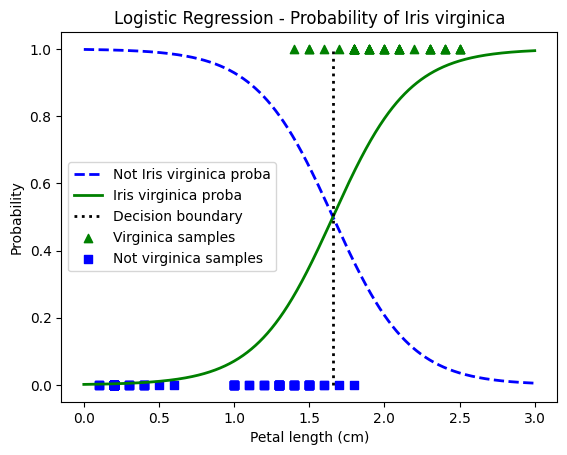

In [109]:
from sklearn.datasets import load_iris
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
import numpy as np

iris = load_iris(as_frame=True)

X = iris.data[["petal width (cm)"]].values
y = iris.target_names[iris.target] == 'virginica'

print(np.unique(y, return_counts=True))  # should show both False and True

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

log_reg = LogisticRegression(random_state=42)
log_reg.fit(X_train, y_train)

X_new = np.linspace(0, 3, 1000).reshape(-1, 1)  # reshape to get a column vector
y_proba = log_reg.predict_proba(X_new)
decision_boundary = X_new[y_proba[:, 1] >= 0.5][0, 0]

plt.plot(X_new, y_proba[:, 0], "b--", linewidth=2,
         label="Not Iris virginica proba")
plt.plot(X_new, y_proba[:, 1], "g-", linewidth=2, label="Iris virginica proba")
plt.plot([decision_boundary, decision_boundary], [0, 1], "k:", linewidth=2,
         label="Decision boundary")

plt.scatter(X_train[y_train], np.ones_like(X_train[y_train]),
            c="g", marker="^", label="Virginica samples")
plt.scatter(X_train[~y_train], np.zeros_like(X_train[~y_train]),
            c="b", marker="s", label="Not virginica samples")
plt.xlabel("Petal length (cm)")
plt.ylabel("Probability")
plt.title("Logistic Regression - Probability of Iris virginica")
plt.legend()
plt.show()

In [118]:
#Softmax Regression
X = iris.data[["petal length (cm)", "petal width (cm)"]].values
y = iris["target"]

X_train, X_test, y_train, y_test = train_test_split(X,y, random_state = 42)

softmax_reg = LogisticRegression(C = 30, random_state = 42)
softmax_reg.fit(X_train, y_train)

print(softmax_reg.predict([[5,2]]))
print(softmax_reg.predict_proba([[5, 2]]).round(2))

[2]
[[0.   0.04 0.96]]
